In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__)
print("Environment verification completed successfully.")


Python version: 3.13.3
Pandas version: 3.0.1
NumPy version: 2.4.3
Matplotlib version: 3.10.9
Seaborn version: 0.13.2
Environment verification completed successfully.


In [2]:
rng = np.random.default_rng(42)          # fixed seed -> same data every run
n = 60

pizzas = ["Margherita", "Pepperoni", "Veggie Supreme", "BBQ Chicken", "Paneer Tikka"]
base_price = {"Margherita": 8, "Pepperoni": 10, "Veggie Supreme": 9,
              "BBQ Chicken": 12, "Paneer Tikka": 11}
size_extra = {"Small": 0, "Medium": 3, "Large": 6}

orders = pd.DataFrame({
    "Order_ID": np.arange(1001, 1001 + n),
    "Order_Date": pd.date_range("2026-09-01", periods=n, freq="D"),
    "Pizza": rng.choice(pizzas, n),
    "Size": rng.choice(["Small", "Medium", "Large"], n, p=[0.3, 0.45, 0.25]),
    "Quantity": rng.integers(1, 5, n),
    "Rating": rng.integers(3, 6, n).astype(float),
})
orders["Unit_Price"] = orders["Pizza"].map(base_price) + orders["Size"].map(size_extra)

# Deliberately add 3 missing ratings and 2 duplicate rows to practise cleaning
orders.loc[[7, 23, 41], "Rating"] = np.nan
orders = pd.concat([orders, orders.iloc[[10, 30]]], ignore_index=True)

orders.to_csv("pizza_orders.csv", index=False)
print("Rows, columns:", orders.shape)
orders.head()


Rows, columns: (62, 7)


,Order_ID,Order_Date,Pizza,Size,Quantity,Rating,Unit_Price
0,1001,2026-09-01,Margherita,Medium,4,3.0,11
1,1002,2026-09-02,BBQ Chicken,Large,1,4.0,18
2,1003,2026-09-03,BBQ Chicken,Medium,2,3.0,15
3,1004,2026-09-04,Veggie Supreme,Medium,3,4.0,12
4,1005,2026-09-05,Veggie Supreme,Medium,2,4.0,12


In [3]:
df = pd.read_csv("pizza_orders.csv", parse_dates=["Order_Date"])

print("First five rows:")
print(df.head())
print("\nLast five rows:")
print(df.tail())
print("\nShape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types and non-null counts:")
df.info()


First five rows:
   Order_ID Order_Date           Pizza    Size  Quantity  Rating  Unit_Price
0      1001 2026-09-01      Margherita  Medium         4     3.0          11
1      1002 2026-09-02     BBQ Chicken   Large         1     4.0          18
2      1003 2026-09-03     BBQ Chicken  Medium         2     3.0          15
3      1004 2026-09-04  Veggie Supreme  Medium         3     4.0          12
4      1005 2026-09-05  Veggie Supreme  Medium         2     4.0          12

Last five rows:
    Order_ID Order_Date           Pizza    Size  Quantity  Rating  Unit_Price
57      1058 2026-10-28      Margherita  Medium         2     4.0          11
58      1059 2026-10-29     BBQ Chicken   Small         2     3.0          12
59      1060 2026-10-30     BBQ Chicken  Medium         3     3.0          15
60      1011 2026-09-11  Veggie Supreme  Medium         3     3.0          12
61      1031 2026-10-01  Veggie Supreme  Medium         2     3.0          12

Shape (rows, columns): (62, 7)

Col

In [4]:
df.describe()

,Order_ID,Order_Date,Quantity,Rating,Unit_Price
count,62.000000,62,62.000000,59.000000,62.000000
mean,1030.193548,2026-09-30 04:38:42.580645,2.451613,3.779661,12.612903
min,1001.000000,2026-09-01 00:00:00,1.000000,3.000000,8.000000
25%,1015.250000,2026-09-15 06:00:00,2.000000,3.000000,10.250000
50%,1030.500000,2026-09-30 12:00:00,2.000000,4.000000,12.000000
75%,1044.750000,2026-10-14 18:00:00,3.000000,4.000000,15.000000
max,1060.000000,2026-10-30 00:00:00,4.000000,5.000000,18.000000
std,17.353451,NaN,1.002904,0.767167,2.955156


In [5]:
print("Missing values before cleaning:")
print(df.isna().sum())
print("\nDuplicate rows before cleaning:", df.duplicated().sum())
print("Rows before cleaning:", len(df))

clean = df.drop_duplicates().copy()
median_rating = clean["Rating"].median()
clean["Rating"] = clean["Rating"].fillna(median_rating)

print("\nMedian rating used to fill missing values:", median_rating)
print("Rows after cleaning:", len(clean))
print("Missing values after cleaning:", clean.isna().sum().sum())
print("Duplicate rows after cleaning:", clean.duplicated().sum())


Missing values before cleaning:
Order_ID      0
Order_Date    0
Pizza         0
Size          0
Quantity      0
Rating        3
Unit_Price    0
dtype: int64

Duplicate rows before cleaning: 2
Rows before cleaning: 62

Median rating used to fill missing values: 4.0
Rows after cleaning: 60
Missing values after cleaning: 0
Duplicate rows after cleaning: 0


In [6]:
clean["Revenue"] = clean["Quantity"] * clean["Unit_Price"]

print("Total revenue:", clean["Revenue"].sum())
print("Average revenue per order:", round(clean["Revenue"].mean(), 2))
print("Median revenue per order:", clean["Revenue"].median())
print("Highest order value:", clean["Revenue"].max())
print("Lowest order value:", clean["Revenue"].min())


Total revenue: 1837
Average revenue per order: 30.62
Median revenue per order: 30.0
Highest order value: 72
Lowest order value: 8


In [7]:
big_orders = clean[clean["Revenue"] > 50]
print("Orders with revenue above 50:", len(big_orders))
print(big_orders[["Order_ID", "Pizza", "Size", "Quantity", "Revenue"]])

print("\nTop 5 orders by revenue:")
top5 = clean.sort_values("Revenue", ascending=False).head(5)
print(top5[["Order_ID", "Pizza", "Size", "Quantity", "Revenue"]])

clean["Order_Type"] = np.where(clean["Revenue"] >= 40, "High value", "Regular")
print("\nOrder types:")
print(clean["Order_Type"].value_counts())


Orders with revenue above 50: 5
    Order_ID         Pizza    Size  Quantity  Revenue
11      1012  Paneer Tikka   Large         3       51
14      1015   BBQ Chicken   Large         4       72
27      1028  Paneer Tikka  Medium         4       56
39      1040   BBQ Chicken  Medium         4       60
42      1043   BBQ Chicken   Large         3       54

Top 5 orders by revenue:
    Order_ID         Pizza    Size  Quantity  Revenue
14      1015   BBQ Chicken   Large         4       72
39      1040   BBQ Chicken  Medium         4       60
27      1028  Paneer Tikka  Medium         4       56
42      1043   BBQ Chicken   Large         3       54
11      1012  Paneer Tikka   Large         3       51

Order types:
Order_Type
Regular       44
High value    16
Name: count, dtype: int64


In [8]:
pizza_summary = clean.groupby("Pizza").agg(
    Orders=("Order_ID", "count"),
    Total_Qty=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum"),
    Avg_Rating=("Rating", "mean")
).sort_values("Total_Revenue", ascending=False).round(2)
print(pizza_summary)

print("\nRevenue by pizza and size:")
print(clean.pivot_table(index="Pizza", columns="Size", values="Revenue",
                        aggfunc="sum", fill_value=0))

print("\nOrder value by size:")
print(clean.groupby("Size")["Revenue"].agg(["count", "mean", "median"]).round(2))


                Orders  Total_Qty  Total_Revenue  Avg_Rating
Pizza                                                       
BBQ Chicken         17         39            615        3.76
Veggie Supreme      15         43            456        4.00
Paneer Tikka        10         24            333        4.00
Margherita          12         29            298        3.50
Pepperoni            6         12            135        3.83

Revenue by pizza and size:
Size            Large  Medium  Small
Pizza                               
BBQ Chicken       216     375     24
Margherita         28     198     72
Paneer Tikka       51     238     44
Pepperoni          16      39     80
Veggie Supreme     30     228    198

Order value by size:
        count   mean  median
Size                        
Large      10  34.10    29.0
Medium     31  34.77    36.0
Small      19  22.00    22.0


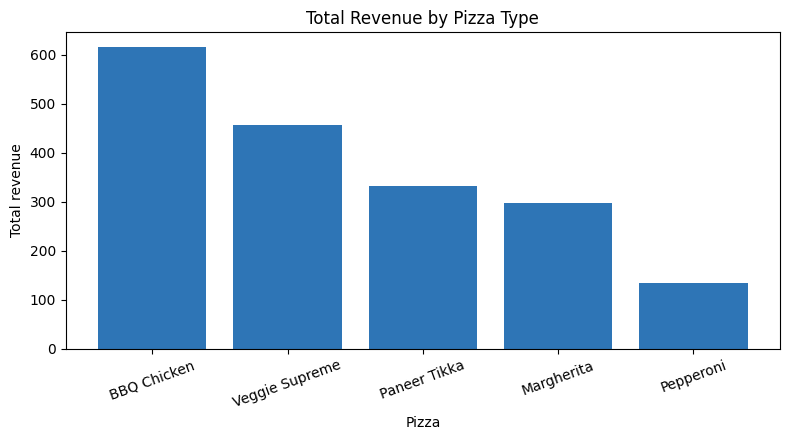

In [9]:
rev = clean.groupby("Pizza")["Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
plt.bar(rev.index, rev.values, color="#2E75B6")
plt.xlabel("Pizza")
plt.ylabel("Total revenue")
plt.title("Total Revenue by Pizza Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


Order_Date
2026-09-06    174
2026-09-13    202
2026-09-20    216
2026-09-27    242
2026-10-04    247
2026-10-11    180
2026-10-18    218
2026-10-25    207
2026-11-01    151
Freq: W-SUN, Name: Revenue, dtype: int64


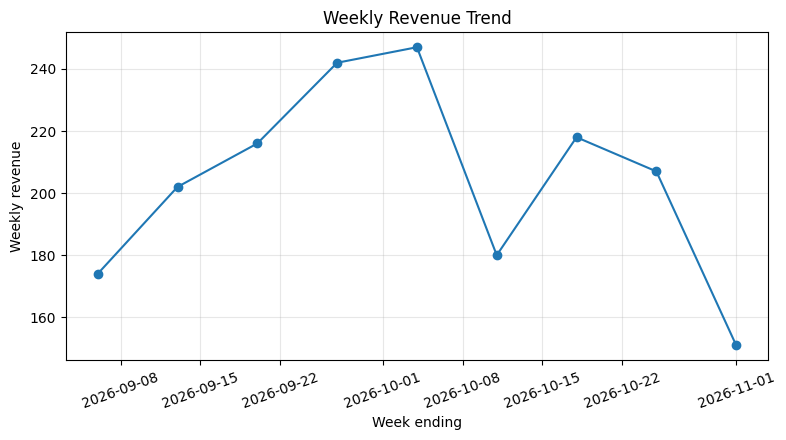

In [10]:
weekly = clean.set_index("Order_Date")["Revenue"].resample("W").sum()
print(weekly)

plt.figure(figsize=(8, 4.5))
plt.plot(weekly.index, weekly.values, marker="o")
plt.xlabel("Week ending")
plt.ylabel("Weekly revenue")
plt.title("Weekly Revenue Trend")
plt.xticks(rotation=20)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


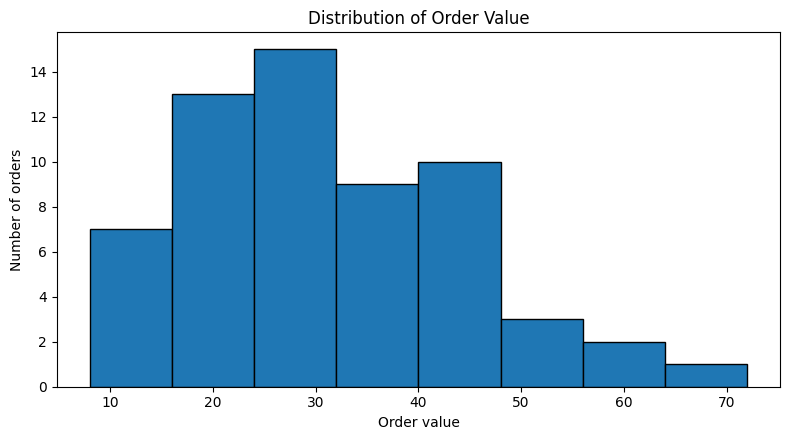

In [11]:
plt.figure(figsize=(8, 4.5))
plt.hist(clean["Revenue"], bins=8, edgecolor="black")
plt.xlabel("Order value")
plt.ylabel("Number of orders")
plt.title("Distribution of Order Value")
plt.tight_layout()
plt.show()


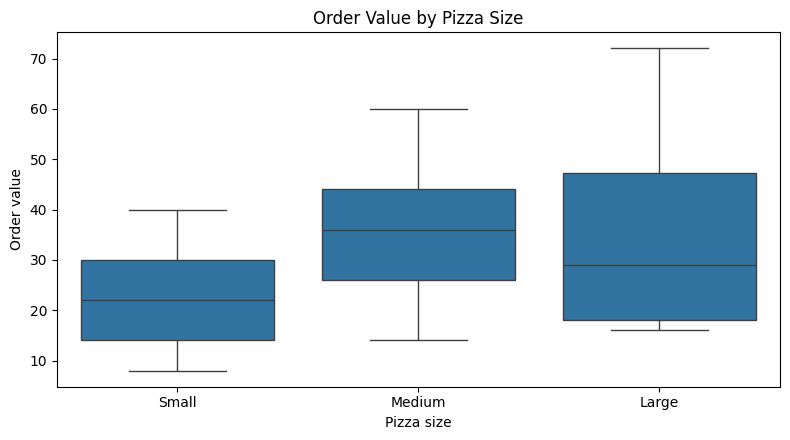

In [12]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=clean, x="Size", y="Revenue", order=["Small", "Medium", "Large"])
plt.xlabel("Pizza size")
plt.ylabel("Order value")
plt.title("Order Value by Pizza Size")
plt.tight_layout()
plt.show()
